# IPSD — Minggu 4: EDA & Visualisasi Data II

**Mata Kuliah:** Infrastruktur dan Platform untuk Sains Data  
**Sub-CLO:** Sub-CLO-09-2-1  
**AI Level:** L2→L3  

**AI Level 2 → Level 3.** Gunakan L2 untuk ide/struktur. Setelah draft analisis/interpretasi selesai, L3 hanya boleh memperbaiki kejelasan bahasa tanpa menambah substansi. Simpan draft sebelum AI, prompt log, dan versi final.

## Capaian Praktikum
- Menganalisis korelasi dan perbandingan antar kelompok.
- Menyusun data story berbasis bukti.
- Membedakan editing bahasa dari penambahan substansi oleh AI.

**Dataset:** Wine dataset atau hasil bersih minggu 3.

## Alur Praktikum
- 1. Membuat correlation matrix dan heatmap dengan matplotlib.
- 2. Membuat grouped summary berdasarkan target/kelas.
- 3. Membuat 2–3 grafik untuk satu data story.
- 4. Menulis insight manual lalu melakukan L3 hanya untuk kejelasan bahasa.

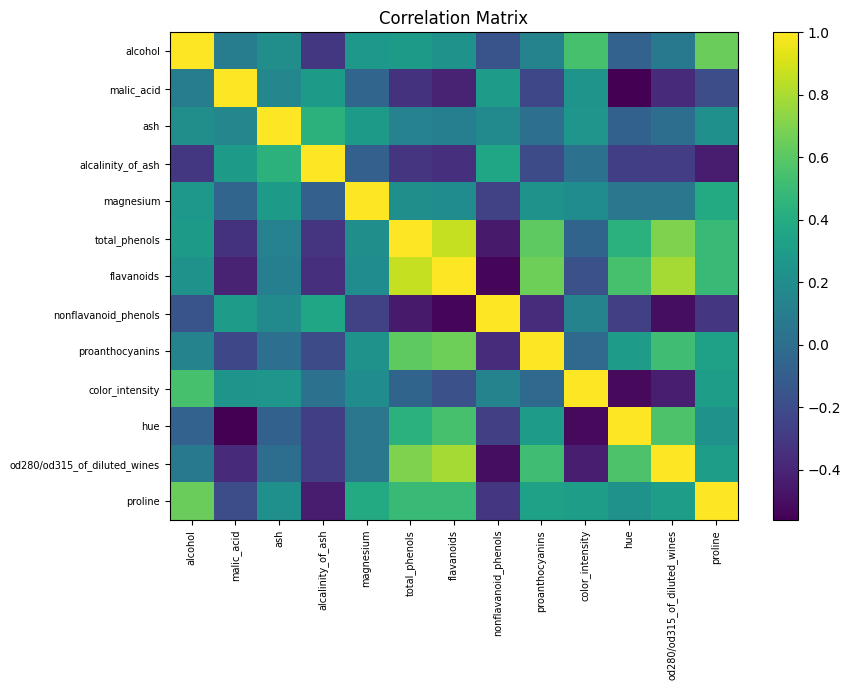

,alcohol,malic_acid,color_intensity
target,,,
0,13.744746,2.010678,5.528305
1,12.278732,1.932676,3.086620
2,13.153750,3.333750,7.396250


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

df = load_wine(as_frame=True).frame.copy()
corr = df.drop(columns=['target']).corr()
fig, ax = plt.subplots(figsize=(9,7))
im = ax.imshow(corr.values, aspect='auto')
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticklabels(corr.columns, fontsize=7)
ax.set_title('Correlation Matrix')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

display(df.groupby('target')[['alcohol','malic_acid','color_intensity']].mean())

## Latihan Terstruktur
- Buat satu klaim analitik dan tunjukkan bukti statistik + visual yang mendukung.
- Identifikasi satu visualisasi yang berpotensi menyesatkan dan perbaiki.
- Nilai sendiri apakah versi AI mengubah substansi; jika ya, kembalikan ke draft mahasiswa.

### 0. cek data dulu
sebelum bikin klaim, aku cek dulu bentuk datanya: ukuran, missing value, dan jumlah per kelas.

In [2]:
import numpy as np

print(df.shape)
print('total missing:', df.isna().sum().sum())
print(df['target'].value_counts().sort_index())

(178, 14)
total missing: 0
target
0    59
1    71
2    48
Name: count, dtype: int64


datanya 178 baris, 13 fitur numerik, tidak ada missing value. jumlah per kelas lumayan seimbang (59 / 71 / 48), jadi perbandingan rata-rata antar kelas masih wajar dilakukan tanpa harus resampling.

### 1. correlation matrix (versi lebih terbaca)
heatmap di sel atas pakai skala warna default dan tidak ada angkanya, jadi susah dibaca. di sini aku kasih angka korelasi dan skala dikunci -1 sampai 1 supaya warnanya tidak menipu.

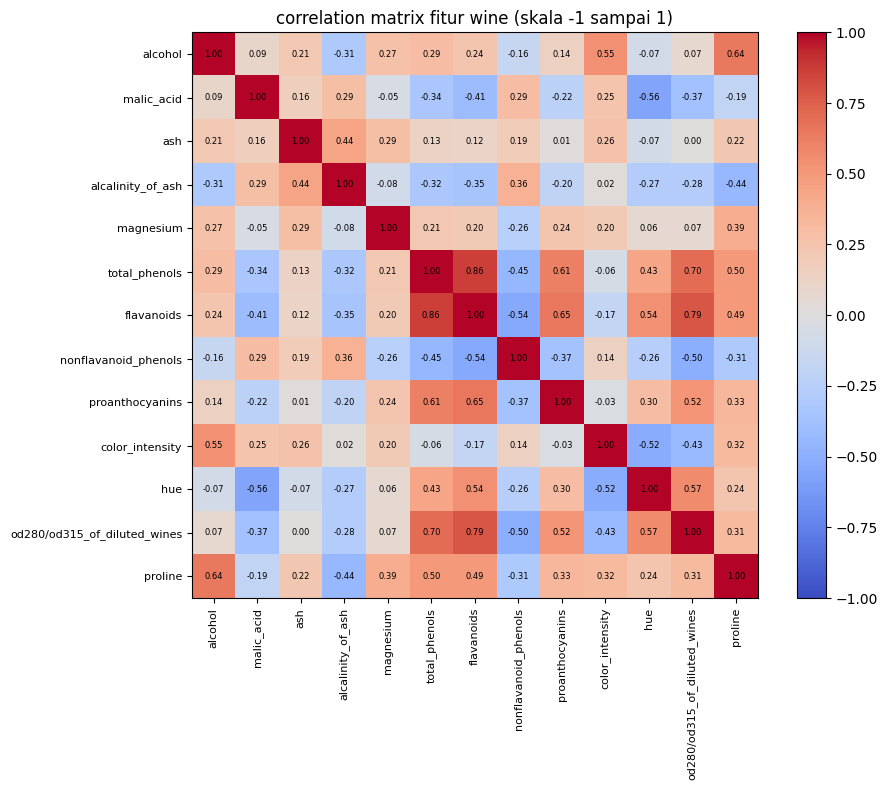

paling negatif:


,fitur_1,fitur_2,r
20,malic_acid,hue,-0.561296
57,flavanoids,nonflavanoid_phenols,-0.537900
72,color_intensity,hue,-0.521813


paling positif:


,fitur_1,fitur_2,r
55,total_phenols,od280/od315_of_diluted_wines,0.699949
61,flavanoids,od280/od315_of_diluted_wines,0.787194
50,total_phenols,flavanoids,0.864564


In [3]:
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=6)
ax.set_title('correlation matrix fitur wine (skala -1 sampai 1)')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

# pasangan fitur dengan korelasi terkuat
pairs = []
cols = list(corr.columns)
for i, a in enumerate(cols):
    for b in cols[i+1:]:
        pairs.append((a, b, corr.loc[a, b]))
pairs = pd.DataFrame(pairs, columns=['fitur_1', 'fitur_2', 'r']).sort_values('r')
print('paling negatif:')
display(pairs.head(3))
print('paling positif:')
display(pairs.tail(3))

korelasi positif paling kuat ada di total_phenols dengan flavanoids (r = 0,86), lalu flavanoids dengan od280/od315 (r = 0,79). masuk akal karena flavanoids itu sendiri bagian dari senyawa fenol. yang paling negatif malic_acid dengan hue (r = -0,56). catatan buat diriku: korelasi cuma ngukur hubungan linear dan tidak bilang sebab-akibat.

### 2. grouped summary per kelas

In [4]:
fitur = ['alcohol', 'malic_acid', 'flavanoids', 'color_intensity', 'proline']
ringkas = df.groupby('target')[fitur].agg(['mean', 'std']).round(2)
display(ringkas)

# korelasi tiap fitur dengan label kelas, cuma buat gambaran kasar
# (target itu kategorik jadi ini bukan ukuran yang rapi, jangan dipakai sebagai bukti utama)
display(df.corr()['target'].drop('target').sort_values().round(2))

alcohol       malic_acid       flavanoids       color_intensity        \
          mean   std       mean   std       mean   std            mean   std   
target                                                                         
0        13.74  0.46       2.01  0.69       2.98  0.40            5.53  1.24   
1        12.28  0.54       1.93  1.02       2.08  0.71            3.09  0.92   
2        13.15  0.53       3.33  1.09       0.78  0.29            7.40  2.31   

        proline          
           mean     std  
target                   
0       1115.71  221.52  
1        519.51  157.21  
2        629.90  115.10

flavanoids                     -0.85
od280/od315_of_diluted_wines   -0.79
total_phenols                  -0.72
proline                        -0.63
hue                            -0.62
proanthocyanins                -0.50
alcohol                        -0.33
magnesium                      -0.21
ash                            -0.05
color_intensity                 0.27
malic_acid                      0.44
nonflavanoid_phenols            0.49
alcalinity_of_ash               0.52
Name: target, dtype: float64

dari tabel ini dua fitur yang rata-ratanya paling beda antar kelas adalah flavanoids dan proline. kelas 0 proline-nya sekitar 1116, jauh di atas kelas 1 (520) dan kelas 2 (630). flavanoids kelas 2 cuma 0,78 sedangkan kelas 0 hampir 3. alcohol dan malic_acid bedanya lebih kecil atau cuma menonjol di satu kelas.

### 3. klaim analitik + bukti
**klaim:** dari lima fitur yang aku bandingkan, flavanoids dan proline paling bisa dipakai untuk membedakan kelas wine. proline memisahkan kelas 0 dari dua kelas lainnya, flavanoids memisahkan kelas 2.

**bukti statistik:** ringkasan lima angka (min, kuartil, median, maks) plus rata-rata dan standar deviasi per kelas, lalu aku hitung berapa persen data kelas lain yang nyasar ke rentang kelas target.

In [5]:
for f in ['flavanoids', 'proline']:
    print(f)
    display(df.groupby('target')[f].describe()[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2))

# seberapa banyak data kelas lain yang nyasar ke rentang kelas target
p0_min = df[df.target == 0]['proline'].min()
fl2_max = df[df.target == 2]['flavanoids'].max()
for k in [1, 2]:
    persen = (df[df.target == k]['proline'] >= p0_min).mean() * 100
    print(f'kelas {k}: {persen:.1f}% datanya proline-nya >= nilai terkecil kelas 0 ({p0_min:.0f})')
for k in [0, 1]:
    persen = (df[df.target == k]['flavanoids'] <= fl2_max).mean() * 100
    print(f'kelas {k}: {persen:.1f}% datanya flavanoids-nya <= nilai terbesar kelas 2 ({fl2_max:.2f})')

flavanoids


,mean,std,min,25%,50%,75%,max
target,,,,,,,
0,2.98,0.40,2.19,2.68,2.98,3.24,3.93
1,2.08,0.71,0.57,1.60,2.03,2.48,5.08
2,0.78,0.29,0.34,0.58,0.68,0.92,1.57


proline


,mean,std,min,25%,50%,75%,max
target,,,,,,,
0,1115.71,221.52,680.0,987.5,1095.0,1280.0,1680.0
1,519.51,157.21,278.0,406.5,495.0,625.0,985.0
2,629.90,115.10,415.0,545.0,627.5,695.0,880.0


kelas 1: 16.9% datanya proline-nya >= nilai terkecil kelas 0 (680)
kelas 2: 31.2% datanya proline-nya >= nilai terkecil kelas 0 (680)
kelas 0: 0.0% datanya flavanoids-nya <= nilai terbesar kelas 2 (1.57)
kelas 1: 19.7% datanya flavanoids-nya <= nilai terbesar kelas 2 (1.57)


untuk proline, median kelas 0 sekitar 1095, sedangkan kelas 1 sekitar 495 dan kelas 2 sekitar 628. kuartil bawah (q1) kelas 0 itu 987,5, bahkan sedikit di atas nilai maksimum kelas 1 (985). artinya sekitar 75% data kelas 0 proline-nya lebih tinggi dari semua data kelas 1. tapi ada kelas 0 yang proline-nya serendah 680 dan sebagian data kelas 1 dan 2 masuk ke rentang itu (17% dan 31%), jadi tidak terpisah sempurna.

untuk flavanoids, nilai terbesar kelas 2 cuma 1,57, sedangkan nilai terkecil kelas 0 adalah 2,19, jadi kelas 0 dan kelas 2 tidak overlap sama sekali. kelas 1 yang agak nyasar: sekitar 20% datanya ada di bawah 1,57. standar deviasi kelas 1 juga paling besar (0,71), jadi sebarannya lebar.

**bukti visual:** boxplot per kelas dan scatter dua fitur tadi.

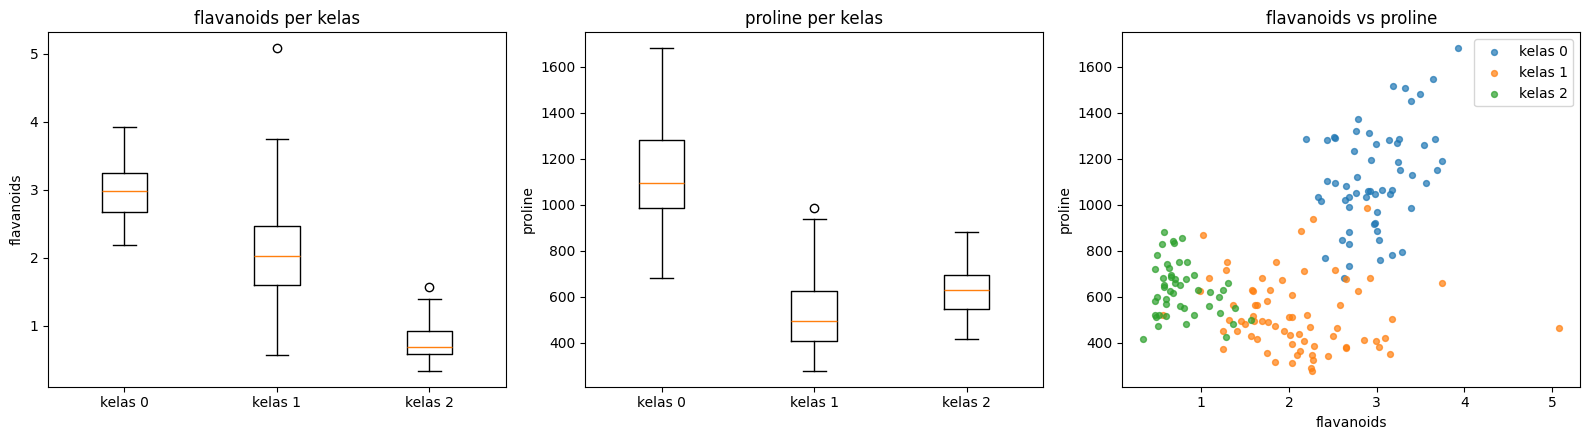

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
warna = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green'}

# boxplot flavanoids
data_fl = [df[df.target == k]['flavanoids'] for k in [0, 1, 2]]
axes[0].boxplot(data_fl)
axes[0].set_xticks([1, 2, 3])
axes[0].set_xticklabels(['kelas 0', 'kelas 1', 'kelas 2'])
axes[0].set_title('flavanoids per kelas')
axes[0].set_ylabel('flavanoids')

# boxplot proline
data_pr = [df[df.target == k]['proline'] for k in [0, 1, 2]]
axes[1].boxplot(data_pr)
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(['kelas 0', 'kelas 1', 'kelas 2'])
axes[1].set_title('proline per kelas')
axes[1].set_ylabel('proline')

# scatter
for k in [0, 1, 2]:
    d = df[df.target == k]
    axes[2].scatter(d['flavanoids'], d['proline'], s=18, alpha=0.7, c=warna[k], label=f'kelas {k}')
axes[2].set_xlabel('flavanoids')
axes[2].set_ylabel('proline')
axes[2].set_title('flavanoids vs proline')
axes[2].legend()

plt.tight_layout()
plt.show()

di boxplot flavanoids, kelas 2 hampir tidak overlap dengan kelas 0 dan cuma sedikit overlap dengan kelas 1. di boxplot proline, kelas 0 jelas paling tinggi, tapi kelas 1 dan 2 overlap banyak. di scatter, ketiga kelas kelihatan membentuk gerombolan yang cukup terpisah kalau dua fitur dipakai bersamaan. jadi satu fitur saja kurang, tapi kombinasi flavanoids + proline lumayan kuat. kelas 1 punya outlier flavanoids yang tinggi (sampai 5,08), jadi aku tidak buang tapi perlu diingat.

### 4. visualisasi yang berpotensi menyesatkan
bar chart rata-rata proline kalau sumbu y tidak mulai dari nol bisa bikin perbedaan kelihatan jauh lebih besar dari aslinya. di bawah ini aku bikin versi yang menyesatkan dulu, lalu versi perbaikannya.

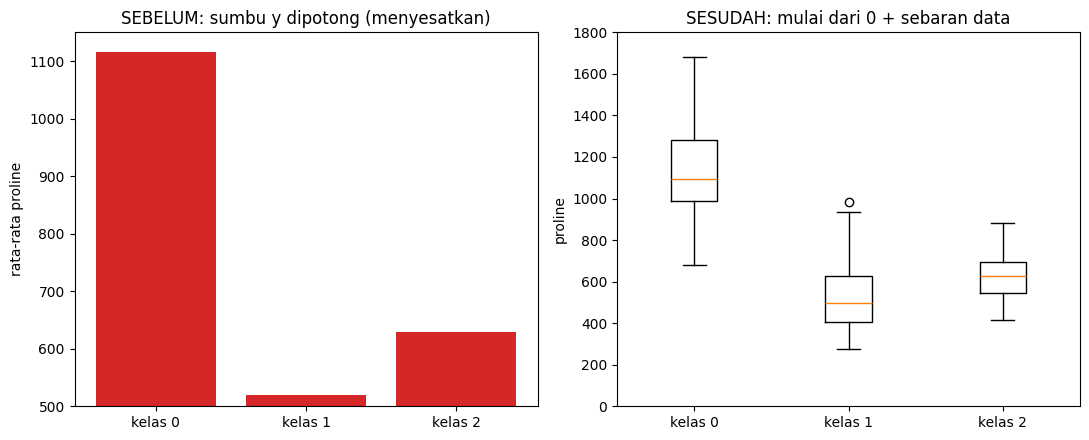

target
0    1115.7
1     519.5
2     629.9
Name: proline, dtype: float64


In [7]:
mean_pr = df.groupby('target')['proline'].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# versi menyesatkan: sumbu y dipotong mulai 500
axes[0].bar(['kelas 0', 'kelas 1', 'kelas 2'], mean_pr.values, color='tab:red')
axes[0].set_ylim(500, 1150)
axes[0].set_title('SEBELUM: sumbu y dipotong (menyesatkan)')
axes[0].set_ylabel('rata-rata proline')

# versi perbaikan: mulai dari nol + tampilkan sebaran lewat boxplot
axes[1].boxplot(data_pr)
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(['kelas 0', 'kelas 1', 'kelas 2'])
axes[1].set_ylim(0, 1800)
axes[1].set_title('SESUDAH: mulai dari 0 + sebaran data')
axes[1].set_ylabel('proline')

plt.tight_layout()
plt.show()
print(mean_pr.round(1))

di versi sebelum, bar kelas 1 kelihatan hampir hilang dan kelas 0 kelihatan raksasa, padahal rata-ratanya 520 vs 1116, sekitar dua kali lipat, bukan belasan kali. selain itu bar rata-rata menyembunyikan sebaran data, padahal kelas 1 dan 2 proline-nya overlap. versi perbaikan pakai sumbu mulai dari 0 dan boxplot supaya sebaran terlihat. dengan ini kesimpulan yang muncul lebih jujur: kelas 0 memang tinggi, tapi kelas 1 dan 2 tidak bisa dibedakan dari proline saja.

## mini data-story: apa yang membedakan tiga kelas wine?

**pertanyaan:** fitur kimia apa yang paling bisa membedakan tiga kelas wine di dataset ini?

**temuan 1 — beberapa fitur saling berkaitan.** di correlation matrix, total_phenols, flavanoids, dan od280/od315 berkorelasi positif kuat (r 0,70 sampai 0,86). artinya ketiganya membawa informasi yang mirip.

**temuan 2 — flavanoids dan proline paling membedakan kelas.** dari lima fitur yang dibandingkan, rata-rata dan median proline kelas 0 (sekitar 1100) kira-kira dua kali lipat kelas 1 dan 2, dan flavanoids kelas 2 (rata-rata 0,78) tidak overlap dengan kelas 0 (nilai terkecilnya 2,19). sekitar 75% data kelas 0 punya proline di atas semua data kelas 1.

**temuan 3 — satu fitur belum cukup.** di boxplot proline, kelas 1 dan 2 overlap banyak. begitu flavanoids dan proline dipakai bersama di scatter plot, ketiga kelas terlihat membentuk gerombolan yang terpisah.

**catatan soal visualisasi.** bar chart rata-rata dengan sumbu y yang dipotong membuat kelas 0 terlihat belasan kali lebih tinggi dari kelas 1, padahal sebenarnya sekitar dua kali. versi perbaikan pakai sumbu mulai dari nol dan boxplot.

**kesimpulan dan batasan.** flavanoids dan proline adalah kandidat fitur terkuat untuk klasifikasi kelas wine. namun ini hanya analisis eksploratif: korelasi bukan sebab-akibat, aku cuma membandingkan lima fitur, dan dataset cuma 178 sampel dari satu sumber, jadi hasilnya belum tentu berlaku untuk wine lain.

## Luaran
Notebook + mini data-story 1 halaman + artefak L3.

**Bukti AI/validasi:** Draft awal; prompt log; final.

## Draft Interpretasi SEBELUM AI — wajib
Tulis interpretasi substantif Anda di sini **sebelum** memakai AI Level 3.

**draft interpretasi (versi aku sendiri, sebelum L3)**

dari correlation matrix, fitur yang berkaitan erat itu total_phenols, flavanoids, dan od280/od315 (r antara 0,70 sampai 0,86). jadi kalau nanti dipakai buat model, ketiganya redundan dan bisa jadi masalah multikolinearitas.

dari grouped summary (rata-rata, median, dan sebaran per kelas), flavanoids dan proline adalah dua fitur yang paling beda antar kelas wine di antara lima fitur yang aku bandingkan. kelas 0 punya proline paling tinggi (rata-rata sekitar 1116) dan flavanoids tinggi, kelas 2 punya flavanoids paling rendah (rata-rata 0,78), sedangkan kelas 1 ada di tengah-tengah untuk flavanoids tapi proline-nya rendah, mirip kelas 2.

dari visual, boxplot dan scatter memperlihatkan bahwa satu fitur belum cukup untuk memisahkan ketiga kelas. proline bagus untuk mengenali kelas 0, flavanoids bagus untuk mengenali kelas 2, dan kalau dipakai bersamaan ketiga kelas cukup terpisah.

batasan: ini analisis deskriptif. korelasi bukan sebab-akibat, dan aku cuma membandingkan lima fitur (bukan semua 13), jadi bisa saja ada fitur lain yang juga membedakan kelas. outlier di kelas 1 tidak aku buang.

## Prompt Log — wajib
| No | Tahap (L2/L3) | Tujuan | Prompt | Apa yang Diubah/Dipakai | Verifikasi bahwa substansi tetap milik mahasiswa |
|---|---|---|---|---|---|
|1|L2|minta bantuan struktur dan kode untuk latihan eda wine (heatmap, grouped summary, grafik)|"kerjakan notebook ipsd m04 pakai bahasa aku, lowercase, gaya mahasiswa semester 3 data sains"|kerangka latihan, kode heatmap berangka, ringkasan statistik per kelas, boxplot, dan contoh grafik menyesatkan|aku jalankan ulang semua sel, cek angka (r, rata-rata, median, kuartil) sama dengan output, dan baca ulang interpretasinya sebelum dipakai|
|2|L3|(isi setelah kamu benar-benar memakai AI untuk merapikan bahasa)|||(tulis apa yang diterima/ditolak)|(tulis bagaimana kamu mengecek tidak ada klaim baru)|

## Versi SETELAH Editing L3
Tempel versi setelah editing. Tandai jika AI mencoba menambahkan klaim/substansi baru dan jelaskan bagaimana Anda menolaknya atau memverifikasinya.

*(bagian ini diisi setelah aku benar-benar melakukan editing L3 pada draft di atas. tempel versi hasil editing di sini, lalu tandai kalau AI menambahkan klaim baru, misalnya soal penyebab perbedaan kimia antar kelas, dan jelaskan kenapa klaim itu ditolak atau dicek dulu.)*

## Refleksi LLM Fluency
Skor diri 1–5: (a) kejelasan tujuan prompt, (b) konteks, (c) constraints, (d) decomposition, (e) iterative refinement, (f) verification. Jelaskan satu contoh peningkatan dari interaksi Anda.

*(isi sendiri sesuai pengalamanmu: skor 1-5 untuk tiap aspek dan satu contoh peningkatan prompt.)*